In [1]:
import polars as pl
import matplotlib.pyplot as plt

data_dir = "data_complete"

data = pl.read_parquet(f"{data_dir}/2026_10_23_17h02.parquet")

In [2]:
results = data.group_by(
    pl.col("f")
).agg(
    pl.col("pow2").max().alias("pmax")
)

In [10]:
dict = {k:[] for k in ["f", "pow", "Ropt", "Cpopt"]}


In [11]:
for f in results["f"]:
    dict["f"].append(f)
    p = results.filter(pl.col("f") == f)["pmax"]
    dict["pow"].append(p)
    dr = data.filter((pl.col("f")==f) & (pl.col("pow2") == p))["Rload"]
    dict["Ropt"].append(dr)
    dc = data.filter((pl.col("f")==f) & (pl.col("pow2") == p))["Cpload"]
    dict["Cpopt"].append(dc)

In [12]:
db = pl.from_dict(dict)

In [13]:
db

f,pow,Ropt,Cpopt
f64,list[f64],list[f64],list[f64]
114.472362,[0.000001],[2.335721e6],[1.9400e-10]
110.577889,[0.000002],[2.335721e6],[2.5291e-9]
115.477387,[6.6863e-7],[1.43845e6],[1.9400e-10]
102.286432,[0.000001],[48329.0],[7.7600e-8]
100.40201,[0.000002],[18330.0],[7.7600e-8]
…,…,…,…
116.482412,[4.7294e-7],[1.43845e6],[1.9400e-10]
95.125628,[1.6020e-7],[78476.0],[1.9400e-10]
110.201005,[0.000002],[3.79269e6],[2.5291e-9]


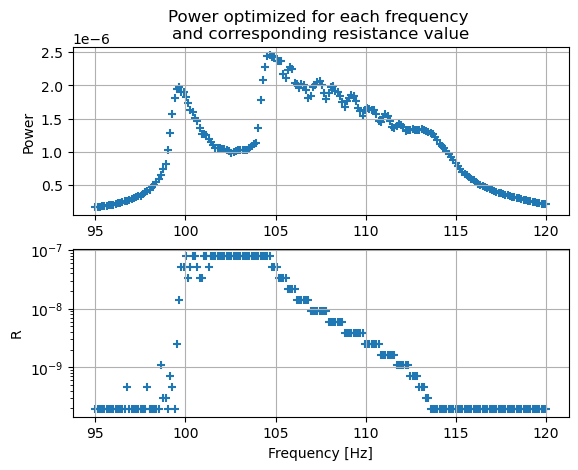

In [15]:
plt.figure()
plt.subplot(2, 1, 1)
plt.scatter(db["f"], db["pow"], marker='+', label = "coupled")
plt.title('Power optimized for each frequency \nand corresponding resistance value')
plt.ylabel('Power')
plt.grid()

plt.subplot(2, 1, 2)
plt.scatter(db["f"], db["Cpopt"], marker='+', label = "coupled")
plt.ylabel('R')
plt.yscale('log')
plt.xlabel('Frequency [Hz]')
plt.grid()

plt.show()

In [16]:

db.write_parquet("results_for_figures/capa_coudemaster_metal.parquet")